In [1]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

In [2]:
df = pd.read_csv('/content/Iris.csv')
df

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...,...
145,146,6.7,3.0,5.2,2.3,Iris-virginica
146,147,6.3,2.5,5.0,1.9,Iris-virginica
147,148,6.5,3.0,5.2,2.0,Iris-virginica
148,149,6.2,3.4,5.4,2.3,Iris-virginica


In [3]:
le = {}
df_enc = df.copy()
for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])
df_enc

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,0,8,14,4,1,0
1,1,6,9,4,1,0
2,2,4,11,3,1,0
3,3,3,10,5,1,0
4,4,7,15,4,1,0
...,...,...,...,...,...,...
145,145,24,9,28,19,2
146,146,20,4,26,15,2
147,147,22,9,28,16,2
148,148,19,13,30,19,2


In [4]:
x = df_enc[['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm']]
y = df_enc['PetalWidthCm']
x


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm
0,0,8,14,4
1,1,6,9,4
2,2,4,11,3
3,3,3,10,5
4,4,7,15,4
...,...,...,...,...
145,145,24,9,28
146,146,20,4,26
147,147,22,9,28
148,148,19,13,30


In [5]:
y

,PetalWidthCm
0,1
1,1
2,1
3,1
4,1
...,...
145,19
146,15
147,16
148,19


In [7]:
model = CategoricalNB()
model.fit(x, y)

CategoricalNB()

In [6]:
test = [['1', '5.1', '3.5', '1.4']]
test

[['1', '5.1', '3.5', '1.4']]

In [13]:
print("\n-----Prediction-----")
for t in test:
  # Using the appropriate Iris dataset features for transformation
  row = [[
      le['Id'].transform([float(t[0])])[0],
      le['SepalLengthCm'].transform([float(t[1])])[0],
      le['SepalWidthCm'].transform([float(t[2])])[0],
      le['PetalLengthCm'].transform([float(t[3])])[0]
  ]]

  pred_encoded = model.predict(row)[0]
  pred = le['PetalWidthCm'].inverse_transform([pred_encoded])[0]
  prob = model.predict_proba(row)[0]

  print(f"Input : Id={t[0]}, SepalLengthCm={t[1]}, SepalWidthCm={t[2]}, PetalLengthCm={t[3]}")
  print(f"Output : PetalWidthCm = {pred}")
  print(f"Result : PetalWidthCm -> {pred}")
  print(f"P(No) = {prob[0]:.4f}, P(Yes) = {prob[1]:.4f}")


-----Prediction-----
Input : Id=1, SepalLengthCm=5.1, SepalWidthCm=3.5, PetalLengthCm=1.4
Output : PetalWidthCm = 0.2
Result : PetalWidthCm -> 0.2
P(No) = 0.0055, P(Yes) = 0.8331


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [14]:
from sklearn.metrics import accuracy_score
y_pred = model.predict(x)
print(f"\nTraining Accuracy: {accuracy_score(y,y_pred) *100:.2f}%")


Training Accuracy: 86.67%


NameError: name 'probs_no' is not defined

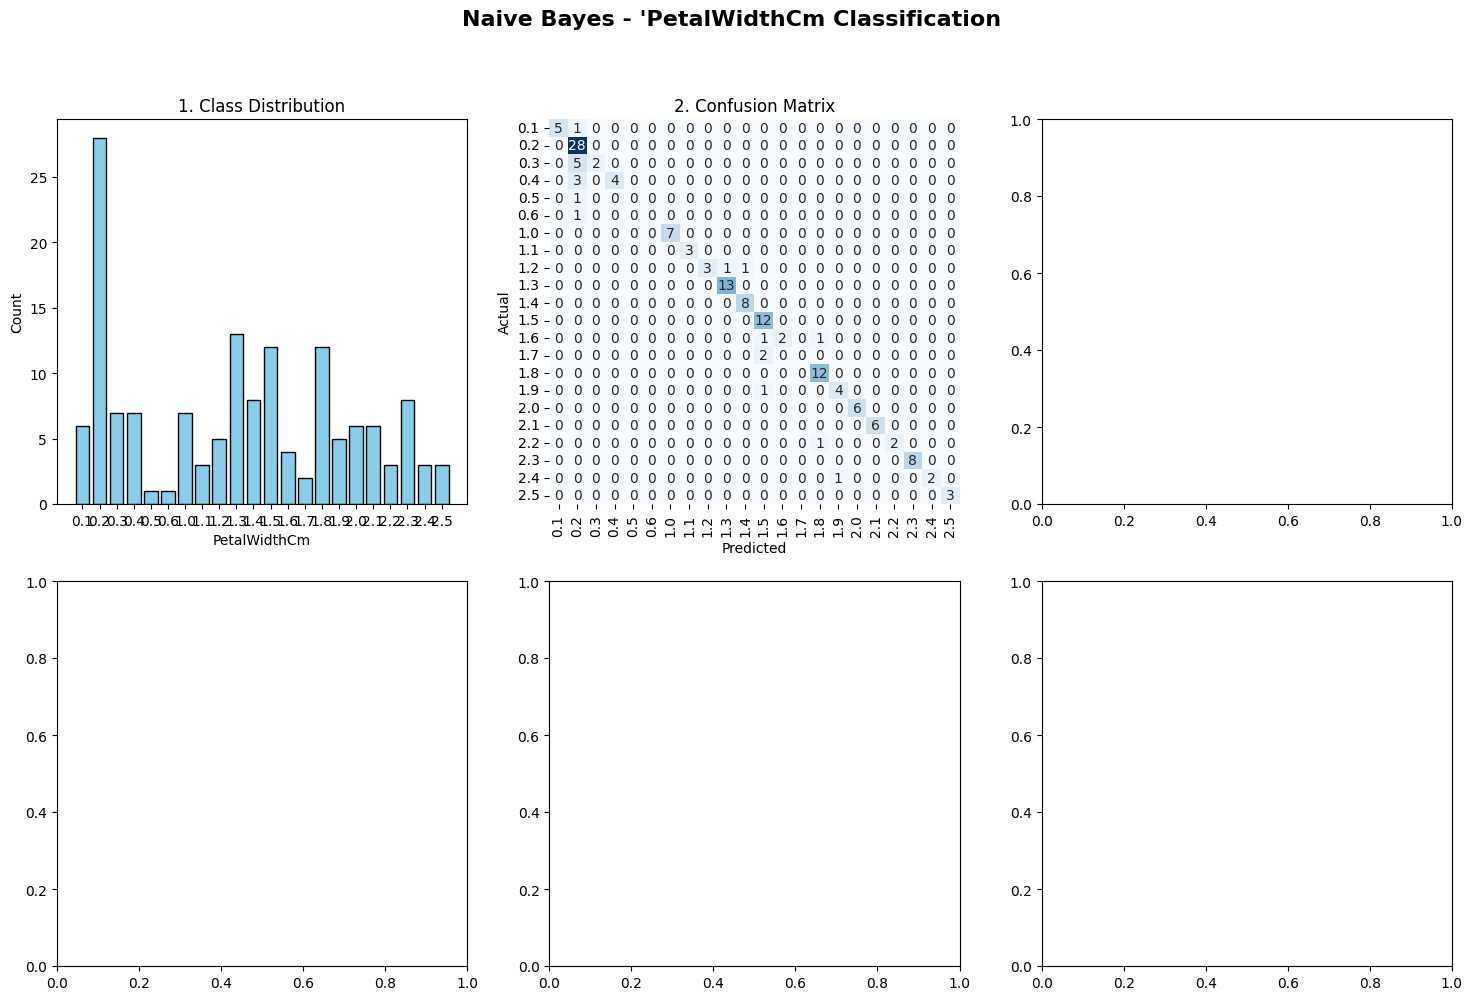

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# Configure subplots
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - 'PetalWidthCm Classification", fontsize=16, fontweight='bold')

# 1. Class Distribution
counts = df['PetalWidthCm'].value_counts().sort_index()
axes[0, 0].bar(counts.index.astype(str), counts.values, color='skyblue', edgecolor='black')
axes[0, 0].set_title("1. Class Distribution")
axes[0, 0].set_xlabel("PetalWidthCm")
axes[0, 0].set_ylabel("Count")


# 2. Confusion Matrix
cm = confusion_matrix(y, model.predict(x))
sns.heatmap(cm, annot=True, cmap='Blues', xticklabels=class_labels, yticklabels=class_labels, ax=axes[0, 1], fmt='d', cbar=False)
axes[0, 1].set_title("2. Confusion Matrix")
axes[0, 1].set_xlabel("Predicted")
axes[0, 1].set_ylabel("Actual")

# Define test cases for visualization
test_cases = ["TC1"]
prob_no = [prob[0]]
prob_yes = [prob[1]]

# 3. Prediction Probabilities for the test case
tc_labels = [f"TC{i+1}" for i in range(len(test_cases))]
x_axis = np.arange(len(tc_labels))
w = 0.3
axes[0, 2].bar(x_axis - w/2, probs_no, w, label='P(No)', color='#e74c3c', edgecolor='black')
axes[0, 2].bar(x_axis + w/2, probs_yes, w, label='P(Yes)', color='#2ecc71', edgecolor='black')
axes[0, 2].set_title("3. Prediction Probabilities")
axes[0, 2].set_ylim(0, 1.1)
axes[0, 2].set_ylabel("Probability")
axes[0, 2].set_xticks(x_axis)
axes[0, 2].set_xticklabels(tc_labels)
axes[0, 2].legend()


# 4. SepalLengthCm vs PetalWidthCm (Grouped Visualization)
age_counts = df.groupby(['Id', 'PetalWidthCm']).size().unstack(fill_value=0)
age_counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0, ax=axes[1, 0])
axes[1, 0].set_title("4. Id vs PetalWidthCm")
axes[1, 0].set_xlabel("Id")
axes[1, 0].set_ylabel("Count")
axes[1, 0].legend(title='PetalWidthCm')


# 5. SepalWidthCm vs PetalWidthCm (Grouped Visualization)
inc_counts = df.groupby(['Id', 'PetalWidthCm']).size().unstack(fill_value=0)
inc_counts.plot(kind='bar', color=['#e74c3c', '#2ecc71'], edgecolor='black', rot=0, ax=axes[1, 1])
axes[1, 1].set_title("5. Id vs PetalWidthCm")
axes[1, 1].set_xlabel("Income")
axes[1, 1].set_ylabel("Count")
axes[1, 1].legend(title='PetalWidthCm')

# 6. Test Case Prediction Summary
pred_value = le['PetalWidthCm'].inverse_transform([model.predict(row)[0]])[0]
axes[1, 2].text(0.5, 0.5, f"TC1 Predicted Result:\n\nPetalWidthCm = {pred_value}",
                fontsize=14, fontweight='bold', ha='center', va='center',
                bbox=dict(facecolor='lightgreen', alpha=0.5, boxstyle='round,pad=1'))
axes[1, 2].axis('off')
axes[1, 2].set_title("6. Test Case Prediction")

plt.tight_layout()
plt.show()